# 05 Preprocess: the extra data (after the test)

**Purpose:** Load and check four extra data sources, state what is known at the cutoff, and build the indicator series for step F: does any public data source improve the forecast beyond the series' own past?
**Input:** `../data/raw/estat_migr_asyappctzm_neighbours_en.csv`, `../data/raw/unhcr_italy_sea_arrivals_by_month.json`, `../data/raw/unhcr_greece_sea_land_arrivals_by_month.csv`, `../data/raw/unhcr_spain_sea_land_arrivals_by_month.csv`, `../data/raw/estat_migr_asyappctzm_ch_by_citizenship_en.csv`, `../data/raw/ucdp_ged261_country_month_deaths.csv`, plus `../data/raw/frontex_detections_by_route_monthly.csv` and `../data/processed/asylum_clean.csv`.
**Output:** `../data/processed/extra_indicators_clean.csv`, `../data/processed/nationality_shares_clean.csv`, `../data/processed/conflict_intensity_clean.csv` and one figure in `../output/figures/`.

**Status.** Steps F to H come **after** the test (`04_test.ipynb`). They do not change our chosen model or its test result. Every new data block is judged on the **backtest only** (2013 to 2024-09), because the test period was already used once. Sources and download dates are in `../data/raw/SOURCES.md`.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. The target, for the checks

We load the target as in `02b` and keep its months: every extra series is put on these months.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")
months = clean.index
mkey = months.strftime("%Y-%m")          # months as text, e.g. "2015-09", to match the raw files

TEST_START = pd.Timestamp("2024-10-01")
print("Target:", months[0].strftime("%Y-%m"), "to", months[-1].strftime("%Y-%m"), "|", len(months), "months")

Target: 2008-01 to 2026-09 | 225 months


## 2. Asylum applications in the neighbouring countries (Eurostat)

The same Eurostat dataset and the same filters as our target, for Germany, Austria, France and Italy (and Switzerland again, as a check). The file is Eurostat's SDMX-CSV format: one row per country and month.

In [3]:
nb_raw = pd.read_csv("../data/raw/estat_migr_asyappctzm_neighbours_en.csv")
print("Rows:", nb_raw.shape[0], "| countries:", sorted(nb_raw["geo"].unique()),
      "| applicant:", nb_raw["applicant"].unique(), "| last update:", nb_raw["LAST UPDATE"].iloc[0])
print("Flags:")
print(nb_raw.loc[nb_raw["OBS_FLAG"].notna(), ["geo", "TIME_PERIOD", "OBS_VALUE", "OBS_FLAG"]].to_string(index=False))

neighbours = nb_raw.pivot(index="TIME_PERIOD", columns="geo", values="OBS_VALUE").reindex(mkey)
neighbours.index = months
same = (neighbours["CH"] == clean["applicants_total"]).sum()
print()
print("Switzerland identical to our target in", same, "of", len(months), "months")
print("Missing months per country:")
print(neighbours[["DE", "AT", "FR", "IT"]].isna().sum().to_string())

Rows: 1124 | countries: ['AT', 'CH', 'DE', 'FR', 'IT'] | applicant: <StringArray>
['TOTAL']
Length: 1, dtype: str | last update: 18/11/26 11:00:00
Flags:
geo TIME_PERIOD  OBS_VALUE OBS_FLAG
 IT     2026-07       5165        b

Switzerland identical to our target in 225 of 225 months
Missing months per country:
geo
DE    1
AT    0
FR    0
IT    0


**What we see.** The file has 1,124 rows: five countries, January 2008 to September 2026, all with applicant type TOTAL (the same definition as our target), Eurostat update of 18 November 2026. **Switzerland is identical to our target in all 225 months**, so the two downloads are consistent. Germany is missing September 2026, and Italy has a break in series (flag `b`) in July 2026, when the new EU asylum rules started. Both are in the test period, which this step does not use.

## 3. Sea and land arrivals (UNHCR) and the Frontex routes

UNHCR's Operational Data Portal publishes monthly arrivals for Italy (by sea), Greece and Spain (sea and land), updated every week, so the whole month $t$ is known at our cutoff. The Italian file was copied from the browser and stops after the data, so we read the monthly values with a text pattern.

*Not seen in class:* `re.findall(pattern, text)` returns every piece of a text that matches a pattern; here, each month's `month`, `year` and `individuals`.

In [4]:
text = open("../data/raw/unhcr_italy_sea_arrivals_by_month.json", encoding="utf-8").read()
found = re.findall(r'\{"month":(\d+),"year":(\d+),"unix_timestamp":\d+,"individuals":(\d+)\}', text)
italy = pd.DataFrame(found, columns=["month", "year", "arrivals"]).astype(int)
italy.index = pd.to_datetime(dict(year=italy["year"], month=italy["month"], day=1))

def read_unhcr_csv(path):
    # UNHCR CSV: first line "sep=;", then month;year;individuals
    data = pd.read_csv(path, sep=";", skiprows=1).dropna()
    data.index = pd.to_datetime(dict(year=data["year"].astype(int), month=data["month"].astype(int), day=1))
    return data["individuals"].astype(float)

unhcr = pd.DataFrame({
    "Italy": italy["arrivals"].astype(float),
    "Greece": read_unhcr_csv("../data/raw/unhcr_greece_sea_land_arrivals_by_month.csv"),
    "Spain": read_unhcr_csv("../data/raw/unhcr_spain_sea_land_arrivals_by_month.csv"),
})
unhcr = unhcr[unhcr.index <= "2026-10-01"]     # November 2026 was not complete at download
print("First month with data:", unhcr.apply(lambda s: s.first_valid_index().strftime("%Y-%m")).to_dict())
print("Yearly totals:")
unhcr.groupby(unhcr.index.year).sum(min_count=1).astype("Int64").tail(6)

First month with data: {'Italy': '2014-01', 'Greece': '2018-01', 'Spain': '2017-01'}
Yearly totals:


,Italy,Greece,Spain
2021,67477,9157,43197
2022,105131,18780,31763
2023,157651,48721,57538
2024,66617,62119,64318
2025,66316,48771,36775
2026,26716,36657,32942


The routes file of `01b` has the same kind of numbers from 2009: Italy is on the Central Mediterranean route, Greece on the Eastern Mediterranean route, Spain on the Western Mediterranean and Western African routes. We compare the monthly changes (in logs) of each UNHCR series with its route.

In [5]:
frontex = pd.read_csv("../data/raw/frontex_detections_by_route_monthly.csv")
frontex["month"] = pd.to_datetime(frontex["month"])
frontex = frontex.set_index("month")

route_of = {"Italy": frontex["central_mediterranean"],
            "Greece": frontex["eastern_mediterranean"],
            "Spain": frontex["western_mediterranean"] + frontex["western_african"]}
for country, route in route_of.items():
    both = pd.concat([unhcr[country], route], axis=1, sort=True).dropna()
    change_corr = np.log1p(both).diff().corr().iloc[0, 1]
    ratio = (both.iloc[:, 0] / both.iloc[:, 1]).median()
    print(f"{country:7s} {both.index[0]:%Y-%m} to {both.index[-1]:%Y-%m} | correlation of monthly log changes: "
          f"{change_corr:.2f} | median ratio UNHCR / Frontex: {ratio:.2f}")

Italy   2014-01 to 2026-09 | correlation of monthly log changes: 0.99 | median ratio UNHCR / Frontex: 1.00
Greece  2018-01 to 2026-09 | correlation of monthly log changes: 0.96 | median ratio UNHCR / Frontex: 0.83
Spain   2017-01 to 2026-09 | correlation of monthly log changes: 0.97 | median ratio UNHCR / Frontex: 1.05


**What we see.** The UNHCR series start in 2014 (Italy), 2017 (Spain) and 2018 (Greece). Their monthly changes move almost exactly like the Frontex routes: correlations of 0.99 (Italy), 0.97 (Spain) and 0.96 (Greece). For Italy the numbers are even the same (median ratio 1.00); Greece is at 0.83 of the Eastern Mediterranean route, which also contains Cyprus and Bulgaria.

**What this means for us.** UNHCR does not bring new information, only **earlier** information: the same numbers, known about one month sooner than in the Frontex file. Step D found that the routes did not help and suspected that they come too late (`03_evaluate.ipynb`, section 7). With UNHCR we can test exactly this.

## 4. Applications in Switzerland by citizenship (Eurostat)

Same dataset again, Switzerland, every citizenship. We need it for the weights of the conflict index: which nationalities came to Switzerland recently. Eurostat writes Namibia as `NA`, so we read the file with `keep_default_na=False`; otherwise pandas would turn Namibia into a missing value.

In [6]:
nat_raw = pd.read_csv("../data/raw/estat_migr_asyappctzm_ch_by_citizenship_en.csv", keep_default_na=False, na_values=[""])
nat = nat_raw.pivot_table(index="TIME_PERIOD", columns="citizen", values="OBS_VALUE", aggfunc="sum").reindex(mkey)
nat.index = months
iso = [c for c in nat.columns if len(c) == 2]          # country codes; the others are groups (EU27_2020, TOTAL, ...)
print("Citizenships:", len(iso), "| TOTAL identical to our target in",
      (nat["TOTAL"] == clean["applicants_total"]).sum(), "of", len(months), "months")

before_test = nat.index < TEST_START
top = (nat.loc[before_test, iso].sum() / nat.loc[before_test, "TOTAL"].sum()).sort_values(ascending=False)
print("Largest shares of all applications, 2008-01 to 2024-09:")
(100 * top.head(10)).round(1)

Citizenships: 199 | TOTAL identical to our target in 225 of 225 months
Largest shares of all applications, 2008-01 to 2024-09:


citizen
ER    15.8
AF    13.1
SY     7.2
TR     7.1
NG     4.6
LK     4.0
DZ     3.6
SO     3.6
IQ     3.5
TN     3.0
dtype: float64

**The weights must be known at the cutoff.** For a forecast origin $t$ we use the share of each nationality in the applications of the 12 months $t-11, \dots, t$, which are all known at the cutoff. The project plan had fixed five origin groups chosen today, which uses hindsight (Johannes' feedback); here the 10 largest groups are chosen again at every origin, from the past 12 months only.

*Not seen in class:* `rolling(12).sum()` adds the current row and the 11 rows before it.

In [7]:
window = nat[iso].rolling(12).sum()
shares = window.div(nat["TOTAL"].rolling(12).sum(), axis=0)      # row t: shares over t-11 ... t
ever_top = sorted(set().union(*[set(shares.loc[m].nlargest(10).index) for m in shares.index[11:]]))
print("Nationalities that are in the top 10 at some origin:", len(ever_top))
print(ever_top)
for m in ["2012-12-01", "2015-09-01", "2021-09-01", "2024-09-01"]:
    t10 = shares.loc[m].nlargest(10)
    print(m[:7], "| top 10 cover", f"{t10.sum():.0%}", "|", ", ".join(f"{c} {v:.0%}" for c, v in t10.head(5).items()))

Nationalities that are in the top 10 at some origin: 22
['AF', 'BI', 'CN', 'DZ', 'ER', 'ET', 'GE', 'GM', 'GN', 'IQ', 'IR', 'LK', 'MA', 'MK', 'NG', 'RS', 'RU', 'SO', 'SY', 'TN', 'TR', 'XK']
2012-12 | top 10 cover 61% | ER 15%, NG 10%, TN 8%, RS 7%, AF 5%
2015-09 | top 10 cover 74% | ER 34%, SY 10%, AF 7%, LK 5%, SO 4%
2021-09 | top 10 cover 80% | AF 19%, ER 15%, TR 15%, SY 7%, DZ 7%
2024-09 | top 10 cover 80% | AF 32%, TR 17%, ER 7%, DZ 7%, SY 5%


**What we see.** The file has 199 citizenships, and its TOTAL is identical to our target in all 225 months. Over 2008 to 2024-09, Eritrea (15.8% of all applications), Afghanistan (13.1%), Syria (7.2%) and Turkey (7.1%) are the largest groups, followed by Nigeria, Sri Lanka, Algeria, Somalia, Iraq and Tunisia (3.0% to 4.6%). The mix changes a lot: at the end of 2012 Nigeria (10%), Tunisia and Serbia were large; in 2015 Eritrea alone was 34%; in 2024 Afghanistan was 32% and Turkey 17%. In total 22 nationalities are in the top 10 at some origin, and the top 10 cover 61% to 80% of all applications.

## 5. Conflict deaths (UCDP)

UCDP's Georeferenced Event Dataset, version 26.1, lists 417,968 events of organised violence from 1989 to 2025, each with an estimate of the deaths. The raw file (274 MB) is too large for the repository. We summed the "best" estimate of deaths per country and month of the event's start (all types of violence) and saved that table. The cell below rebuilds it if the raw file is placed in `../data/raw/`.

**Known at the cutoff?** Johannes asked this question for the yearly file, and the answer is no: version 26.1 was published in 2026 and is revised every year. UCDP also publishes monthly "Candidate" data about one month later, so we use conflict months up to $t-1$ only. Still, our numbers are the final, revised ones, which a planner did not have at the time: **this test is optimistic for the conflict data.** If the conflict index does not help even so, it would not help with the data really available.

In [8]:
import os
if os.path.exists("../data/raw/GEDEvent_v26_1.csv"):
    ged_events = pd.read_csv("../data/raw/GEDEvent_v26_1.csv", usecols=["country", "date_start", "best"])
    ged_events["month"] = ged_events["date_start"].str[:7]
    rebuilt = ged_events.groupby(["country", "month"])["best"].sum().unstack(0)
    print("Rebuilt from the raw file:", rebuilt.shape)
else:
    print("Raw GED file not in data/raw/: we use the stored table")

ged = pd.read_csv("../data/raw/ucdp_ged261_country_month_deaths.csv", index_col=0)
print("Stored table:", ged.shape[1], "countries,", ged.index[0], "to", ged.index[-1])

Raw GED file not in data/raw/: we use the stored table


Stored table: 126 countries, 1989-01 to 2025-12


Eurostat writes countries as two-letter codes, UCDP by name. We match every nationality that is ever in the top 10. UCDP counts Kosovo inside "Serbia (Yugoslavia)".

In [9]:
ISO_TO_GED = {"AF": "Afghanistan", "BI": "Burundi", "CN": "China", "DZ": "Algeria", "ER": "Eritrea", "ET": "Ethiopia",
              "GE": "Georgia", "GM": "Gambia", "GN": "Guinea", "IQ": "Iraq", "IR": "Iran", "LK": "Sri Lanka",
              "MA": "Morocco", "MK": "North Macedonia", "NG": "Nigeria", "RS": "Serbia (Yugoslavia)",
              "RU": "Russia (Soviet Union)", "SO": "Somalia", "SY": "Syria", "TN": "Tunisia", "TR": "Turkey",
              "XK": "Serbia (Yugoslavia)"}
assert set(ever_top) <= set(ISO_TO_GED), set(ever_top) - set(ISO_TO_GED)
print("Not in UCDP (no recorded events, counted as 0 deaths):",
      [c for c in ever_top if ISO_TO_GED[c] not in ged.columns])

grid = pd.period_range("2007-01", "2026-09", freq="M").strftime("%Y-%m")
intensity = pd.DataFrame(index=grid)
for c in ever_top:
    name = ISO_TO_GED[c]
    deaths = ged[name].reindex(grid) if name in ged.columns else pd.Series(0.0, index=grid)
    intensity[c] = np.log1p(deaths.fillna(0.0))            # log(1 + deaths): a month without events counts as 0
intensity.loc[intensity.index > "2025-12"] = np.nan        # version 26.1 ends in December 2025
intensity.index = pd.to_datetime(intensity.index)
print("Deaths per year in the main origins (thousands):")
(np.expm1(intensity[["AF", "SY", "ER", "TR", "SO", "NG"]]).groupby(intensity.index.year).sum() / 1000).loc[2012:2024].round(1).T

Not in UCDP (no recorded events, counted as 0 deaths): []
Deaths per year in the main origins (thousands):


,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
AF,7.8,8.1,12.5,18.0,19.0,19.8,26.9,30.4,20.8,36.4,1.7,0.4,0.4
SY,53.7,76.5,78.7,59.6,53.9,38.5,21.7,11.2,5.7,2.0,1.7,2.2,3.6
ER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
TR,0.8,0.1,0.0,1.1,1.6,0.5,0.5,0.3,0.2,0.1,0.1,0.1,0.0
SO,3.0,1.0,1.2,1.3,2.1,2.1,2.5,2.2,2.1,2.3,3.1,4.2,2.4
NG,2.0,3.4,10.3,9.1,4.0,3.6,3.2,2.5,3.1,3.2,3.0,4.2,3.2


**What we see.** The stored table has 126 countries from 1989 to 2025, and every nationality of our list is in it. The deaths match the known history: Syria with 50,000 to 80,000 deaths a year in 2012 to 2016, Afghanistan rising to 36,400 in 2021 and almost no deaths from 2022 (after the Taliban took power). **Eritrea, the largest group in our data, has 0 recorded deaths in every year:** people leave Eritrea because of repression and forced military service, not because of battles. The conflict index can therefore not see the main driver of the Eritrean applications.

## 6. What is known at the cutoff

At the cutoff around the 15th of month $m$, the forecast origin is $t = m-1$ (as in `01b`). For each new input, the newest month we may use:

| Input | Published | Used at origin $t$ |
|---|---|---|
| Applications in Germany + Austria + France + Italy (Eurostat) | about 6 weeks after the month (Switzerland's September 2026 appeared on 13 November) | up to $t-1$ |
| Sea and land arrivals Italy + Greece + Spain (UNHCR, weekly updates) | within days | up to $t$ |
| Shares of nationalities in Swiss applications (SEM, with the target) | with the target | up to $t$ |
| Conflict deaths (UCDP Candidate, monthly) | about one month later | up to $t-1$ (final values: optimistic) |

**Arrivals: which history?** Section 3 showed that the UNHCR numbers are the Frontex route numbers. UNHCR's Italian series starts only in 2014 and Spain's in 2017, but Frontex goes back to 2009. So we use the **Frontex route numbers from 2009, at the UNHCR timing $t$**. This adds one month of information compared with step D, where the routes were used at $t-1$. One more difference: here we take the four Mediterranean routes (Central, Eastern, Western Mediterranean and Western African), the routes of Italy, Greece and Spain, while step D used the Central and Eastern Mediterranean and the Western Balkans.

## 7. Build the indicator series

As in `01b`, we save the indicators as **logs**, month by month; the changes are built in the estimation notebook. For the conflict index we save the two inputs (shares and log deaths), because the index for origin $t$ uses the weights of $t$ (see `05b`).

| Column | Formula |
|---|---|
| `log_neighbours` | $\log$(applications in DE + AT + FR + IT) |
| `log_med_routes` | $\log(1 + \text{detections on the four Mediterranean routes})$; one month (2010-02) had 0 on the Central Mediterranean route |

In [10]:
fx = frontex.reindex(months)
extra = pd.DataFrame(index=months)
extra["log_neighbours"] = np.log(neighbours[["DE", "AT", "FR", "IT"]].sum(axis=1, min_count=4))
extra["log_med_routes"] = np.log1p(fx["central_mediterranean"] + fx["eastern_mediterranean"]
                                   + fx["western_mediterranean"] + fx["western_african"])
extra.index.name = "month"
print(extra.describe().round(2))
print("Missing:", extra.isna().sum().to_dict())

       log_neighbours  log_med_routes
count          224.00          213.00
mean            10.21            9.30
std              0.68            0.84
min              8.87            7.17
25%              9.61            8.73
50%             10.36            9.33
75%             10.67            9.73
max             11.67           12.33
Missing: {'log_neighbours': 1, 'log_med_routes': 12}


## 8. Exploration before the test period

As in `01b`, we look only at the months before the test period. Do the monthly changes of an indicator move together with the change in applications in the same month, or in the following months (a lead)? We correlate the change of each indicator in month $s$ with the change of log applications in month $s + k$, for $k = 0, 1, 2, 3$.

For the conflict deaths we use the weighted sum over the top 10 nationalities of each month (weights of that month, as in the index of `05b`).

In [11]:
log_y = clean["log_applicants"]
weighted_deaths = pd.Series(np.nan, index=months)
for i, m in enumerate(months):
    w = shares.loc[m]
    if w.isna().all() or m > pd.Timestamp("2025-12-01"):
        continue
    t10 = w.nlargest(10)
    weighted_deaths[m] = float((t10 * intensity.loc[m, t10.index]).sum())

series = {"Neighbours (Eurostat)": extra["log_neighbours"], "Med routes (Frontex)": extra["log_med_routes"],
          "Weighted conflict deaths (UCDP)": weighted_deaths}
rows = []
for name, s in series.items():
    for k in range(4):
        both = pd.DataFrame({"ind": s.diff(), "app": log_y.diff().shift(-k)})
        both = both[both.index < TEST_START - pd.DateOffset(months=k)].dropna()
        rows.append({"indicator": name, "k (months later)": k, "correlation": both["ind"].corr(both["app"])})
pd.DataFrame(rows).pivot(index="indicator", columns="k (months later)", values="correlation").round(2)

k (months later),0,1,2,3
indicator,,,,
Med routes (Frontex),0.26,0.32,0.09,0.15
Neighbours (Eurostat),0.59,0.05,-0.04,-0.07
Weighted conflict deaths (UCDP),0.12,0.04,-0.03,-0.01


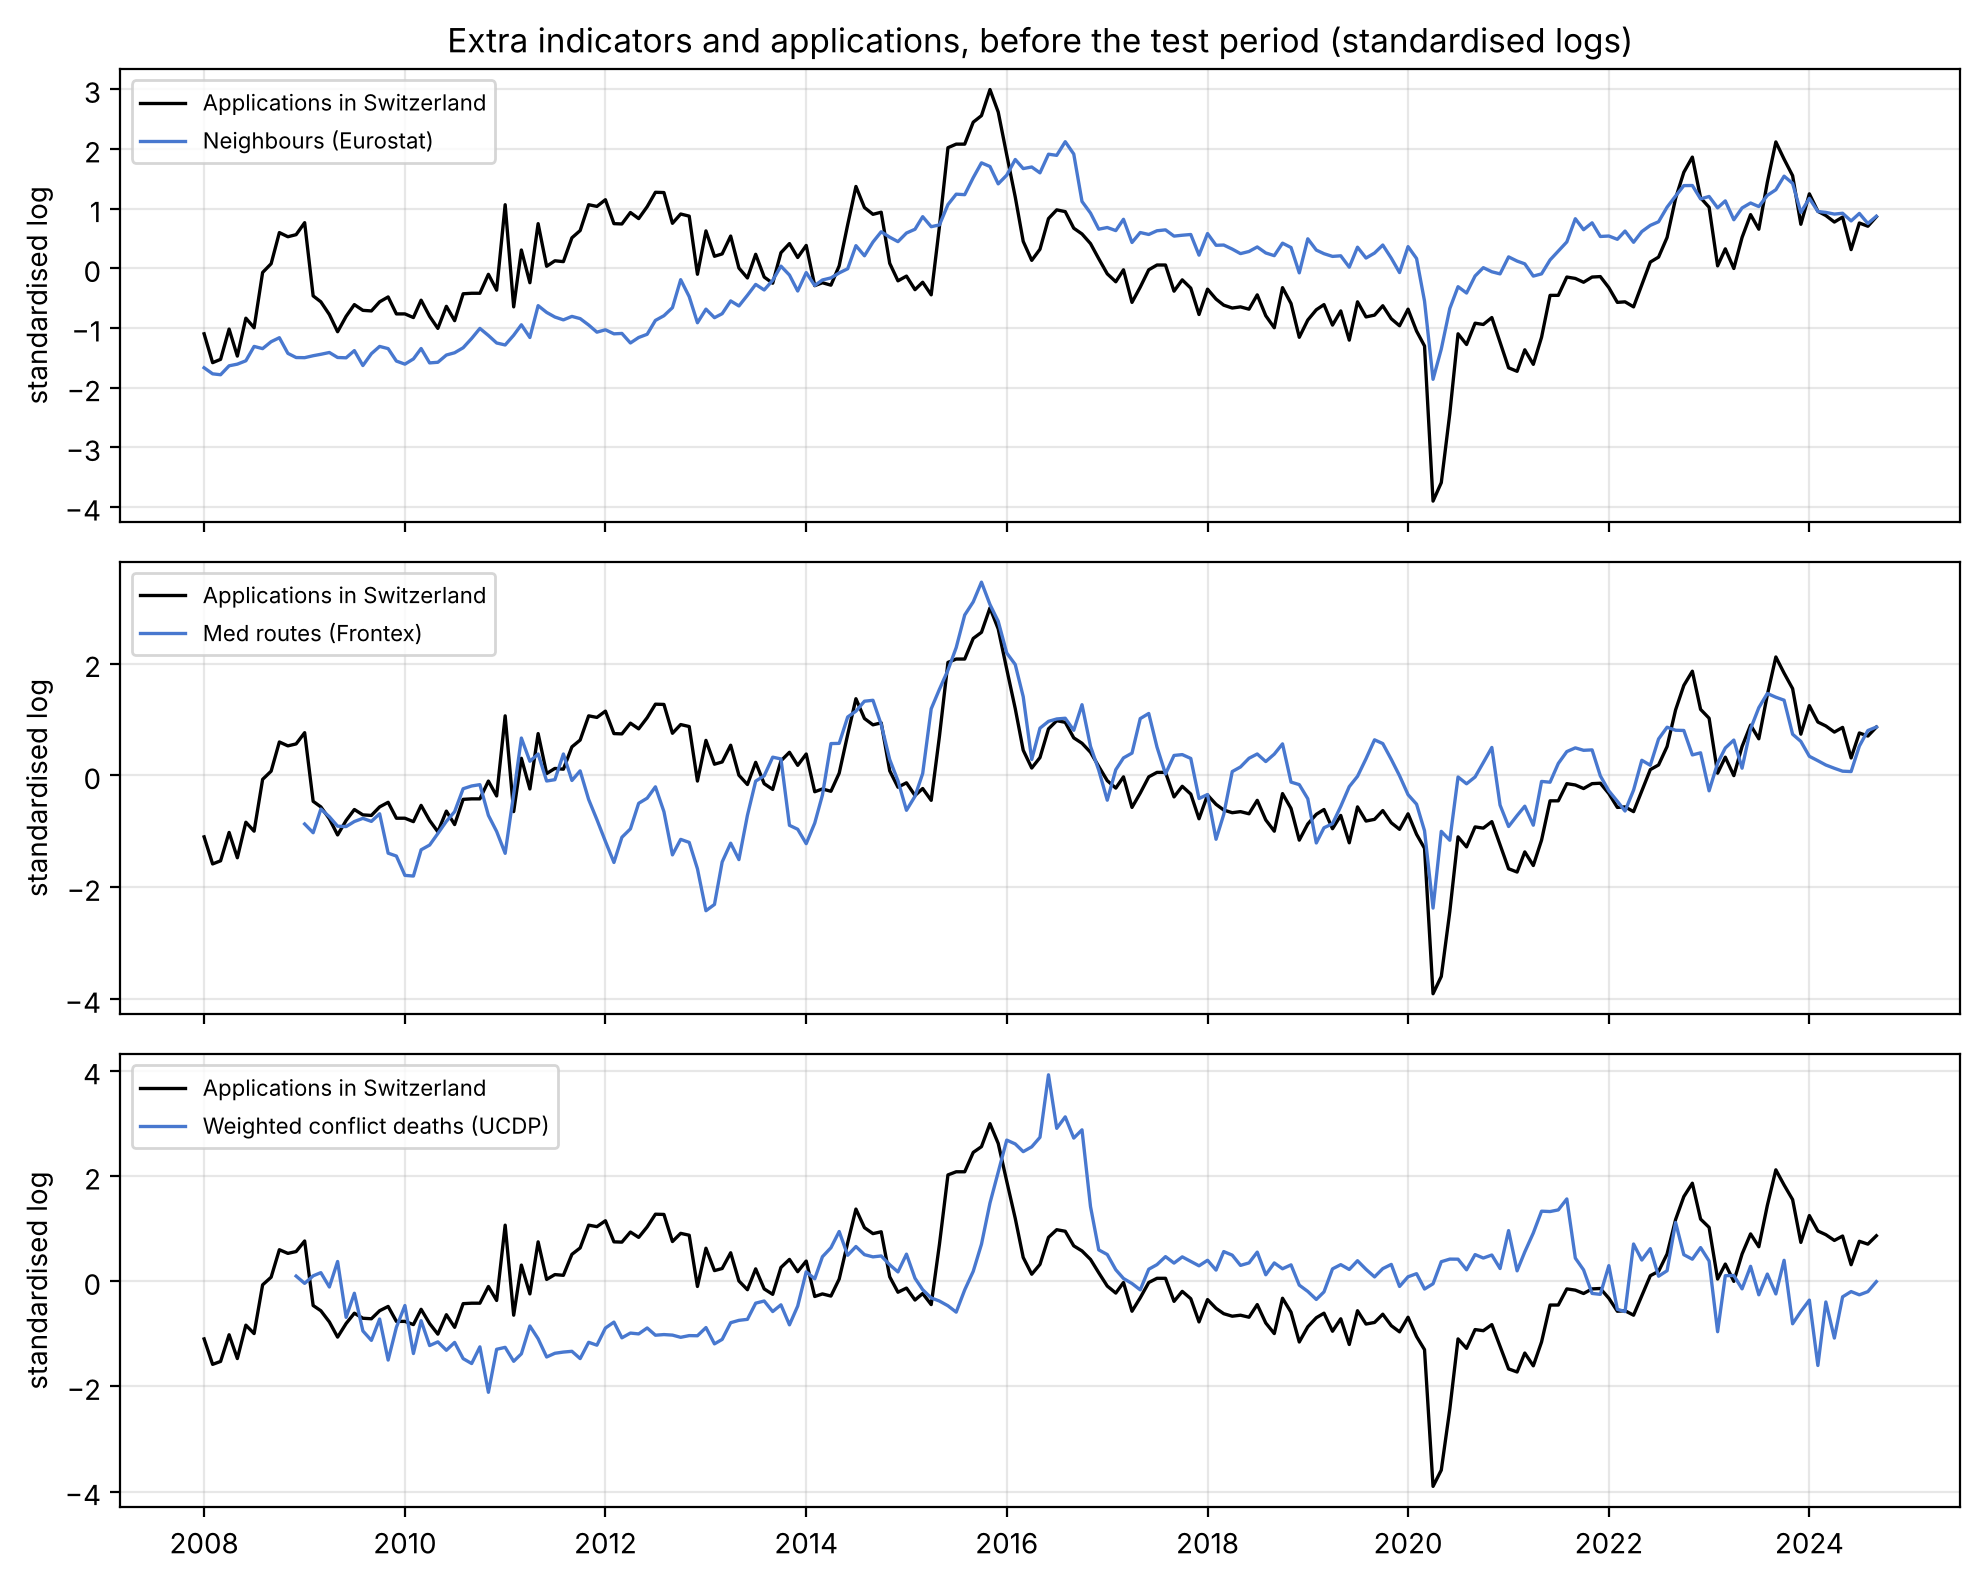

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
before = months < TEST_START
for ax, (name, s) in zip(axes, series.items()):
    a = (log_y - log_y[before].mean()) / log_y[before].std()
    z = (s - s[before].mean()) / s[before].std()
    ax.plot(months[before], a[before], color="black", lw=1.2, label="Applications in Switzerland")
    ax.plot(months[before], z[before], lw=1.2, label=name)
    ax.set_ylabel("standardised log")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)
axes[0].set_title("Extra indicators and applications, before the test period (standardised logs)")
plt.tight_layout()
plt.savefig("../output/figures/05_extra_indicators_and_applications.png")
plt.show()

**What we see.**
- **Neighbours:** the change in applications in Germany, Austria, France and Italy moves strongly with the Swiss change **in the same month** (correlation 0.59), but not with the following months (0.05, −0.04, −0.07). And at the cutoff we only know the neighbours up to $t-1$.
- **Mediterranean routes:** the correlation is 0.26 in the same month and 0.32 one month later, then smaller (0.09 and 0.15). Like the routes of `01b`, they move together with Swiss applications and one month ahead, not more.
- **Conflict deaths:** small correlations at every lag (0.12 to −0.03).
- In the figure, the neighbours and the routes follow the big swings of the Swiss series (2015-16, 2020, 2022-23). The weighted conflict deaths peak only in 2016, after the Swiss peak: partly because the weights follow the nationalities that had just arrived (Syrians, Afghans).

**What this means for us.** A lead of one month is exactly what UNHCR's timing ($t$ instead of $t-1$) can use, so the routes are the most promising block. The neighbours look strong, but only in the same month, which we cannot know at the cutoff. Whether any of this improves the forecasts is checked in `05b`.

## 9. Save

In [13]:
extra.to_csv("../data/processed/extra_indicators_clean.csv")

shares_out = shares[ever_top].copy()
shares_out.index.name = "month"
shares_out.to_csv("../data/processed/nationality_shares_clean.csv")

intensity_out = intensity.copy()
intensity_out.index.name = "month"
intensity_out.to_csv("../data/processed/conflict_intensity_clean.csv")
print("Saved:", extra.shape, shares_out.shape, intensity_out.shape)

Saved: (225, 2) (225, 22) (237, 22)


## Summary

- **Four extra sources**, all checked: applications in Germany, Austria, France and Italy (Eurostat, the same dataset as our target; Switzerland identical in 225 of 225 months); monthly arrivals in Italy, Greece and Spain (UNHCR); Swiss applications by citizenship (Eurostat; TOTAL identical to the target); conflict deaths by country and month (UCDP GED 26.1).
- **UNHCR = Frontex:** the UNHCR arrivals are the Frontex route numbers (correlations of monthly changes 0.96 to 0.99), published about one month earlier. We use the Frontex history from 2009 at the UNHCR timing $t$.
- **Known at the cutoff:** neighbours up to $t-1$, arrivals up to $t$, nationality shares up to $t$, conflict deaths up to $t-1$. The conflict data are final values, not those available at the time: an optimistic test.
- **Nationality weights without hindsight:** the 10 largest groups are chosen again at every origin, from the past 12 months.
- **Exploration (before the test period):** the neighbours move with Swiss applications in the same month only (0.59, then about 0); the routes in the same month and one month later (0.26 and 0.32); the conflict deaths hardly at all. Eritrea has no recorded conflict deaths.
- **Not seen in class (marked above):** `re.findall`, `rolling(12).sum()`.
- **Output:** `extra_indicators_clean.csv`, `nationality_shares_clean.csv`, `conflict_intensity_clean.csv` in `../data/processed/`, and `05_extra_indicators_and_applications.png`.